In [1264]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import scipy
import statsmodels
import xgboost

print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


In [1265]:
df=pd.read_csv(r"C:\Users\acer\Desktop\AI_Data_Analytics\supply_chain_demand_forecasting_dataset.csv")
df.head()

,Order_Date,Product_ID,Product_Name,Category,Quantity_Sold,Unit_Price_INR,Inventory_Stock,Lead_Time_Days,Revenue_INR
0,2024-01-01,P001,Laptop,Electronics,8,42000,243,8,336000
1,2024-01-01,P002,Mobile,Electronics,27,18000,304,6,486000
2,2024-01-01,P003,Headphones,Accessories,38,2500,682,5,95000
3,2024-01-01,P004,Keyboard,Accessories,38,1500,540,7,57000
4,2024-01-01,P005,Office Chair,Furniture,19,6500,328,10,123500


In [1266]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7310 entries, 0 to 7309
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Order_Date       7310 non-null   object
 1   Product_ID       7310 non-null   object
 2   Product_Name     7310 non-null   object
 3   Category         7310 non-null   object
 4   Quantity_Sold    7310 non-null   int64 
 5   Unit_Price_INR   7310 non-null   int64 
 6   Inventory_Stock  7310 non-null   int64 
 7   Lead_Time_Days   7310 non-null   int64 
 8   Revenue_INR      7310 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 514.1+ KB


In [1267]:
df.isnull().sum()

Order_Date         0
Product_ID         0
Product_Name       0
Category           0
Quantity_Sold      0
Unit_Price_INR     0
Inventory_Stock    0
Lead_Time_Days     0
Revenue_INR        0
dtype: int64

In [1268]:
df.duplicated().sum()

np.int64(0)

In [1269]:
df.describe()

,Quantity_Sold,Unit_Price_INR,Inventory_Stock,Lead_Time_Days,Revenue_INR
count,7310.000000,7310.00000,7310.000000,7310.000000,7310.000000
mean,26.158550,10400.00000,442.745144,7.500000,183597.127223
std,16.043139,11685.31897,260.397240,2.291445,174521.012522
min,4.000000,800.00000,94.000000,4.000000,20000.000000
25%,14.000000,2500.00000,244.000000,6.000000,70500.000000
50%,21.000000,7500.00000,352.000000,7.500000,110500.000000
75%,35.000000,12000.00000,593.000000,9.000000,204000.000000
max,111.000000,42000.00000,1525.000000,12.000000,924000.000000


In [1270]:
df=df.drop_duplicates()
df.dtypes

Order_Date         object
Product_ID         object
Product_Name       object
Category           object
Quantity_Sold       int64
Unit_Price_INR      int64
Inventory_Stock     int64
Lead_Time_Days      int64
Revenue_INR         int64
dtype: object

In [1271]:
product_sales = df.groupby("Product_Name")["Revenue_INR"].sum()

product_sales

Product_Name
Desk             69246000
Headphones       77980000
Keyboard         40828500
Laptop          386316000
Mobile          348570000
Monitor         146808000
Mouse            33824000
Office Chair     91182000
Printer          92556500
Webcam           54784000
Name: Revenue_INR, dtype: int64

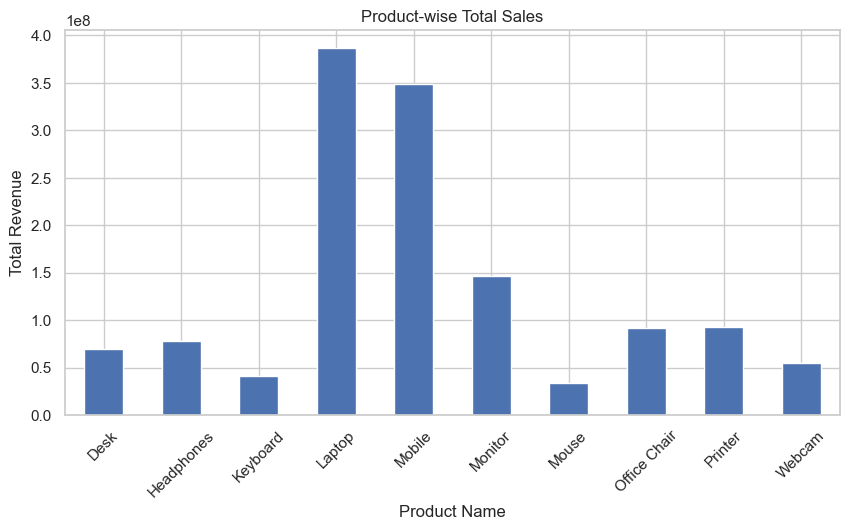

In [1272]:
product_sales.plot(kind="bar", figsize=(10,5))

plt.title("Product-wise Total Sales")
plt.xlabel("Product Name")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.show()

In [1273]:
product_sales = df.groupby("Product_Name")["Revenue_INR"].sum()

highest_product = product_sales.idxmax()
highest_revenue = product_sales.max()

print("Highest Selling Product:", highest_product)
print("Total Revenue:", highest_revenue)

Highest Selling Product: Laptop
Total Revenue: 386316000


In [1274]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

In [1275]:
monthly_sales = df.groupby(df["Order_Date"].dt.to_period("M"))["Revenue_INR"].sum()

monthly_sales

Order_Date
2024-01    53410000
2024-02    50483900
2024-03    52751600
2024-04    54058200
2024-05    53710200
2024-06    58433800
2024-07    58223800
2024-08    54159800
2024-09    52322700
2024-10    64142300
2024-11    60228400
2024-12    61929900
2025-01    51754000
2025-02    46781200
2025-03    53716500
2025-04    51409700
2025-05    54324600
2025-06    54961800
2025-07    59420500
2025-08    54998500
2025-09    50170700
2025-10    63743600
2025-11    63258400
2025-12    63700900
Freq: M, Name: Revenue_INR, dtype: int64

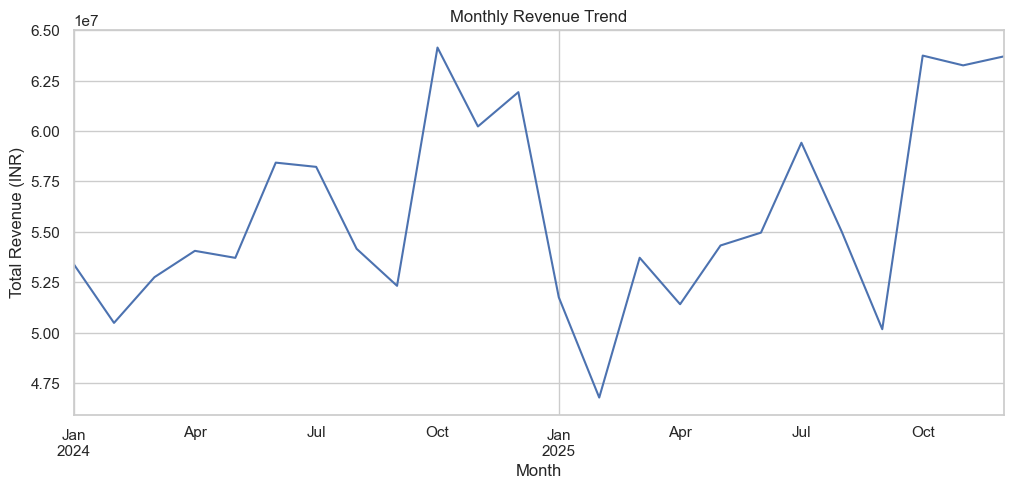

In [1276]:
monthly_sales.plot(figsize=(12, 5))

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue (INR)")
plt.show()

In [1277]:
monthly_demand = df.groupby(df["Order_Date"].dt.to_period("M"))["Quantity_Sold"].sum()

monthly_demand

Order_Date
2024-01    7467
2024-02    7130
2024-03    7595
2024-04    7547
2024-05    7636
2024-06    8046
2024-07    8156
2024-08    7742
2024-09    7552
2024-10    9160
2024-11    8554
2024-12    9330
2025-01    7358
2025-02    6716
2025-03    7843
2025-04    7345
2025-05    7742
2025-06    7883
2025-07    8313
2025-08    7702
2025-09    7272
2025-10    8965
2025-11    8960
2025-12    9205
Freq: M, Name: Quantity_Sold, dtype: int64

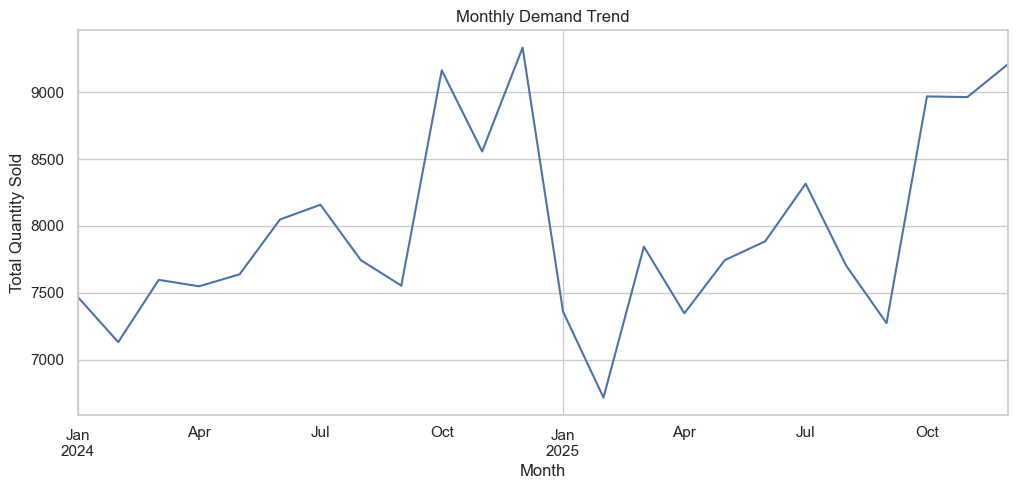

In [1278]:
monthly_demand.plot(figsize=(12, 5))

plt.title("Monthly Demand Trend")
plt.xlabel("Month")
plt.ylabel("Total Quantity Sold")
plt.show()

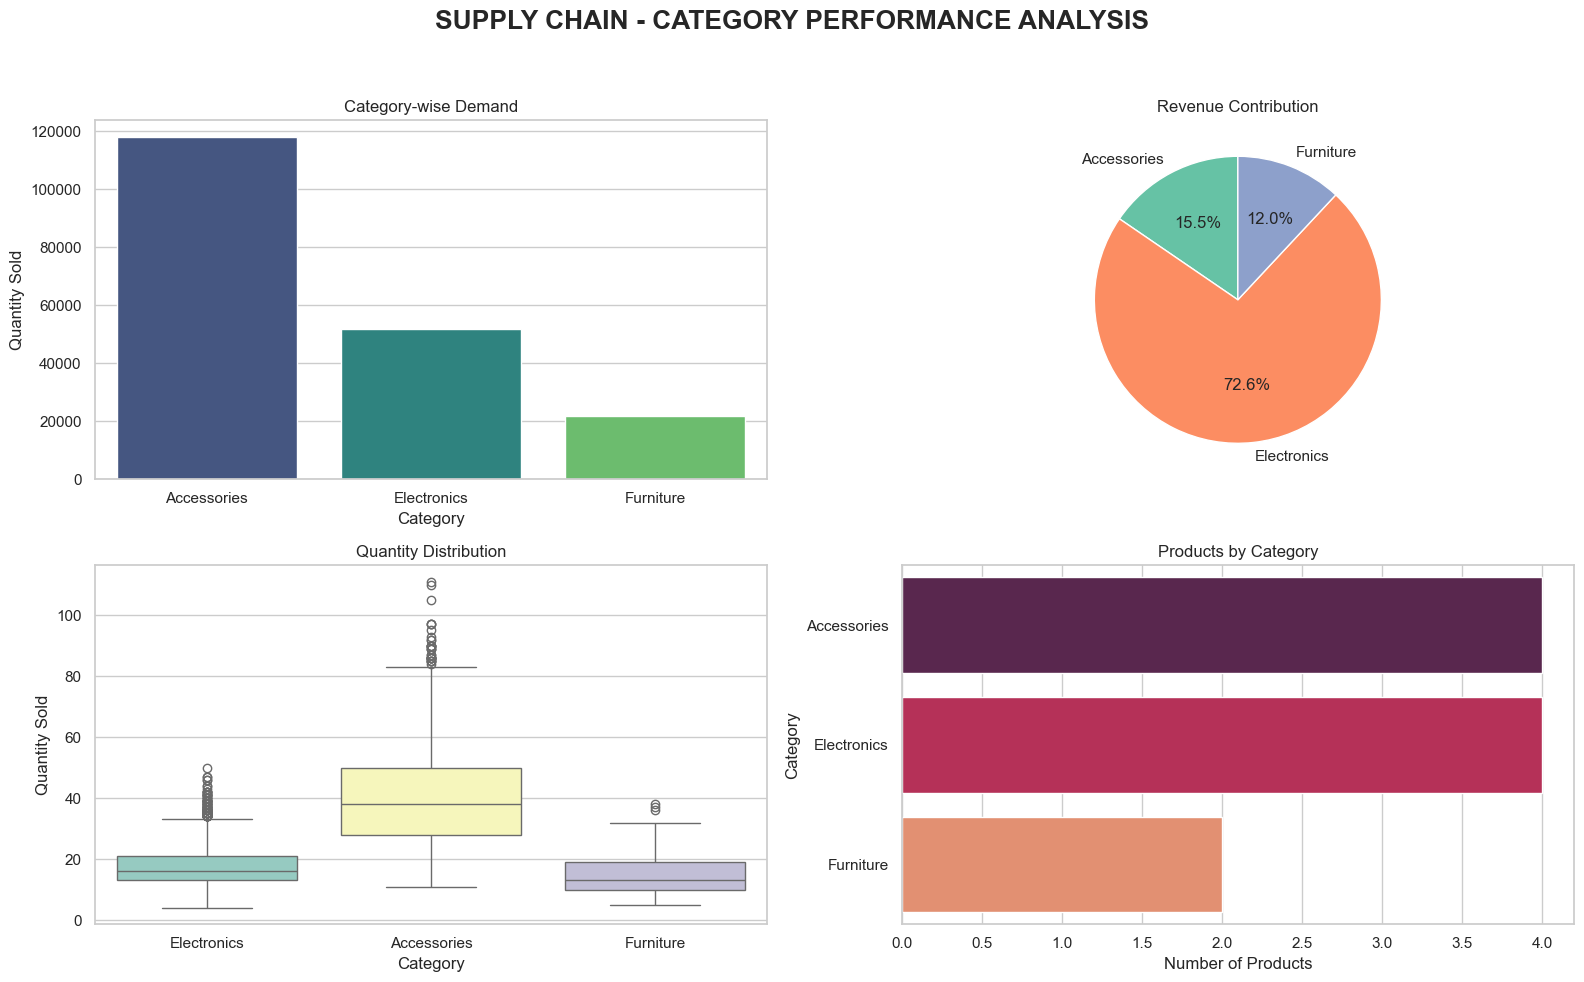

In [1279]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# Dashboard style
sns.set_theme(style="whitegrid")

# Category summary
category_summary = df.groupby("Category").agg(
    Quantity_Sold=("Quantity_Sold", "sum"),
    Revenue_INR=("Revenue_INR", "sum"),
    Average_Quantity=("Quantity_Sold", "mean"),
    Product_Count=("Product_Name", "nunique")
).reset_index()


# Create 4 charts in one dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 10))


# Chart 1 - Demand Analysis
sns.barplot(
    data=category_summary,
    x="Category",
    y="Quantity_Sold",
    palette="viridis",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Category-wise Demand")
axes[0, 0].set_xlabel("Category")
axes[0, 0].set_ylabel("Quantity Sold")


# Chart 2 - Revenue Contribution
axes[0, 1].pie(
    category_summary["Revenue_INR"],
    labels=category_summary["Category"],
    autopct="%1.1f%%",
    colors=sns.color_palette("Set2", len(category_summary)),
    startangle=90
)
axes[0, 1].set_title("Revenue Contribution")


# Chart 3 - Quantity Distribution
sns.boxplot(
    data=df,
    x="Category",
    y="Quantity_Sold",
    palette="Set3",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Quantity Distribution")
axes[1, 0].set_xlabel("Category")
axes[1, 0].set_ylabel("Quantity Sold")


# Chart 4 - Product Count
sns.barplot(
    data=category_summary,
    x="Product_Count",
    y="Category",
    palette="rocket",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Products by Category")
axes[1, 1].set_xlabel("Number of Products")
axes[1, 1].set_ylabel("Category")


# Main Dashboard Heading
fig.suptitle(
    "SUPPLY CHAIN - CATEGORY PERFORMANCE ANALYSIS",
    fontsize=19,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [1280]:
monthly_product = df.groupby(
    [df["Order_Date"].dt.to_period("M"), "Product_ID", "Product_Name"]
)["Quantity_Sold"].sum().reset_index()

monthly_product.head(10)

,Order_Date,Product_ID,Product_Name,Quantity_Sold
0,2024-01,P001,Laptop,390
1,2024-01,P002,Mobile,739
2,2024-01,P003,Headphones,1224
3,2024-01,P004,Keyboard,1063
4,2024-01,P005,Office Chair,511
5,2024-01,P006,Desk,312
6,2024-01,P007,Monitor,488
7,2024-01,P008,Printer,432
8,2024-01,P009,Mouse,1654
9,2024-01,P010,Webcam,654


In [1281]:
monthly_product = monthly_product.sort_values(
    ["Product_ID", "Order_Date"]
)

monthly_product["Previous_Month_Demand"] = (
    monthly_product.groupby("Product_ID")["Quantity_Sold"].shift(1)
)

monthly_product.head(10)

,Order_Date,Product_ID,Product_Name,Quantity_Sold,Previous_Month_Demand
0,2024-01,P001,Laptop,390,NaN
10,2024-02,P001,Laptop,369,390.0
20,2024-03,P001,Laptop,352,369.0
30,2024-04,P001,Laptop,377,352.0
40,2024-05,P001,Laptop,354,377.0
50,2024-06,P001,Laptop,409,354.0
60,2024-07,P001,Laptop,401,409.0
70,2024-08,P001,Laptop,368,401.0
80,2024-09,P001,Laptop,362,368.0
90,2024-10,P001,Laptop,434,362.0


In [1282]:
monthly_product["Two_Months_Ago_Demand"] = (
    monthly_product.groupby("Product_ID")["Quantity_Sold"].shift(2)
)

monthly_product.head(10)

,Order_Date,Product_ID,Product_Name,Quantity_Sold,Previous_Month_Demand,Two_Months_Ago_Demand
0,2024-01,P001,Laptop,390,NaN,NaN
10,2024-02,P001,Laptop,369,390.0,NaN
20,2024-03,P001,Laptop,352,369.0,390.0
30,2024-04,P001,Laptop,377,352.0,369.0
40,2024-05,P001,Laptop,354,377.0,352.0
50,2024-06,P001,Laptop,409,354.0,377.0
60,2024-07,P001,Laptop,401,409.0,354.0
70,2024-08,P001,Laptop,368,401.0,409.0
80,2024-09,P001,Laptop,362,368.0,401.0
90,2024-10,P001,Laptop,434,362.0,368.0


In [1283]:
monthly_product[[
    "Product_ID",
    "Order_Date",
    "Quantity_Sold",
    "Previous_Month_Demand",
    "Two_Months_Ago_Demand"
]].head(15)

,Product_ID,Order_Date,Quantity_Sold,Previous_Month_Demand,Two_Months_Ago_Demand
0,P001,2024-01,390,NaN,NaN
10,P001,2024-02,369,390.0,NaN
20,P001,2024-03,352,369.0,390.0
30,P001,2024-04,377,352.0,369.0
40,P001,2024-05,354,377.0,352.0
50,P001,2024-06,409,354.0,377.0
60,P001,2024-07,401,409.0,354.0
70,P001,2024-08,368,401.0,409.0
80,P001,2024-09,362,368.0,401.0
90,P001,2024-10,434,362.0,368.0


In [1284]:
monthly_product["Previous_3_Month_Avg_Demand"] = (
    monthly_product.groupby("Product_ID")["Quantity_Sold"]
    .transform(lambda x: x.shift(1).rolling(3).mean())
)

monthly_product.head(10)

,Order_Date,Product_ID,Product_Name,Quantity_Sold,Previous_Month_Demand,Two_Months_Ago_Demand,Previous_3_Month_Avg_Demand
0,2024-01,P001,Laptop,390,NaN,NaN,NaN
10,2024-02,P001,Laptop,369,390.0,NaN,NaN
20,2024-03,P001,Laptop,352,369.0,390.0,NaN
30,2024-04,P001,Laptop,377,352.0,369.0,370.333333
40,2024-05,P001,Laptop,354,377.0,352.0,366.000000
50,2024-06,P001,Laptop,409,354.0,377.0,361.000000
60,2024-07,P001,Laptop,401,409.0,354.0,380.000000
70,2024-08,P001,Laptop,368,401.0,409.0,388.000000
80,2024-09,P001,Laptop,362,368.0,401.0,392.666667
90,2024-10,P001,Laptop,434,362.0,368.0,377.000000


In [1285]:
monthly_product["Month_Number"] = monthly_product["Order_Date"].dt.month

monthly_product.head()

,Order_Date,Product_ID,Product_Name,Quantity_Sold,Previous_Month_Demand,Two_Months_Ago_Demand,Previous_3_Month_Avg_Demand,Month_Number
0,2024-01,P001,Laptop,390,NaN,NaN,NaN,1
10,2024-02,P001,Laptop,369,390.0,NaN,NaN,2
20,2024-03,P001,Laptop,352,369.0,390.0,NaN,3
30,2024-04,P001,Laptop,377,352.0,369.0,370.333333,4
40,2024-05,P001,Laptop,354,377.0,352.0,366.000000,5


In [1286]:
monthly_product["Year"] = monthly_product["Order_Date"].dt.year

monthly_product.head()

,Order_Date,Product_ID,Product_Name,Quantity_Sold,Previous_Month_Demand,Two_Months_Ago_Demand,Previous_3_Month_Avg_Demand,Month_Number,Year
0,2024-01,P001,Laptop,390,NaN,NaN,NaN,1,2024
10,2024-02,P001,Laptop,369,390.0,NaN,NaN,2,2024
20,2024-03,P001,Laptop,352,369.0,390.0,NaN,3,2024
30,2024-04,P001,Laptop,377,352.0,369.0,370.333333,4,2024
40,2024-05,P001,Laptop,354,377.0,352.0,366.000000,5,2024


In [1287]:
monthly_product.isnull().sum()

Order_Date                      0
Product_ID                      0
Product_Name                    0
Quantity_Sold                   0
Previous_Month_Demand          10
Two_Months_Ago_Demand          20
Previous_3_Month_Avg_Demand    30
Month_Number                    0
Year                            0
dtype: int64

In [1288]:
monthly_product = monthly_product.dropna()

In [1289]:
print(monthly_product.shape)

(210, 9)


In [1290]:
print(monthly_product.columns)

Index(['Order_Date', 'Product_ID', 'Product_Name', 'Quantity_Sold',
       'Previous_Month_Demand', 'Two_Months_Ago_Demand',
       'Previous_3_Month_Avg_Demand', 'Month_Number', 'Year'],
      dtype='object')


In [1291]:
# input columns
X = monthly_product[[
    "Previous_Month_Demand",
    "Two_Months_Ago_Demand",
    "Previous_3_Month_Avg_Demand",
    "Month_Number",
    "Year"
]]
# target variable
y = monthly_product["Quantity_Sold"]

print("X Shape:", X.shape)
print("Y Shape:", y.shape)

X Shape: (210, 5)
Y Shape: (210,)


In [1292]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
    )

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (168, 5)
Testing Data: (42, 5)


In [1293]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model Training Completed Successfully")

Model Training Completed Successfully


In [1294]:
y_pred = model.predict(X_test)

print(y_pred[:10])

[1615.35805616 1618.68841074 1621.70340275 1701.22513455 1767.6331202
 1807.85043458 1847.16951504 1943.20139467 1917.15189799 2026.35533264]


In [1295]:
comparison = pd.DataFrame({
    "Actual_Demand": y_test.values,
    "Predicted_Demand": y_pred
})

comparison.head(10)

,Actual_Demand,Predicted_Demand
0,1642,1615.358056
1,1600,1618.688411
2,1740,1621.703403
3,1854,1701.225135
4,1759,1767.633120
5,1742,1807.850435
6,2009,1847.169515
7,1868,1943.201395
8,2222,1917.151898
9,1520,2026.355333


In [1296]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 86.06445100952463
RMSE: 127.50347559720879
R2 Score: 0.945792190598684


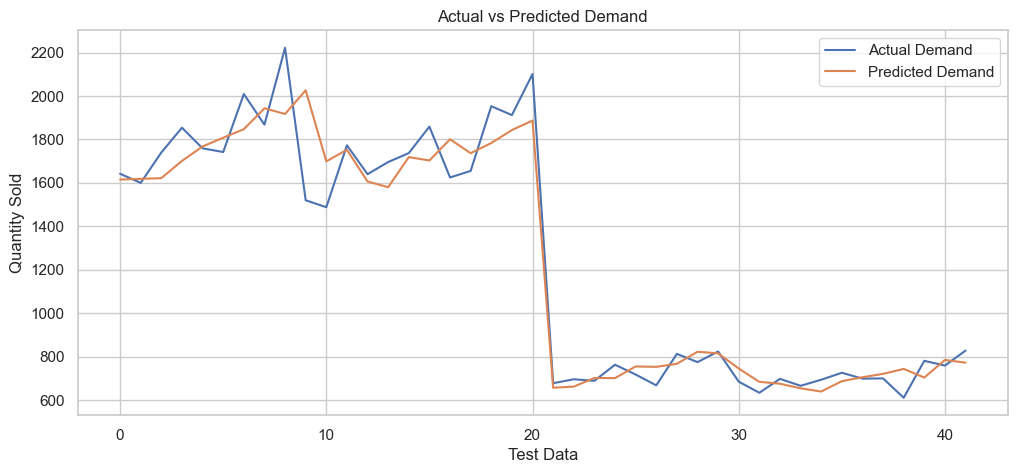

In [1297]:
plt.figure(figsize=(12, 5))

plt.plot(y_test.values, label="Actual Demand")
plt.plot(y_pred, label="Predicted Demand")

plt.title("Actual vs Predicted Demand")
plt.xlabel("Test Data")
plt.ylabel("Quantity Sold")
plt.legend()
plt.show()

In [1298]:
# product wise pridiction results
prediction_results = monthly_product.loc[
    y_test.index,
    ["Order_Date", "Product_ID", "Product_Name"]
].copy()

prediction_results["Actual_Demand"] = y_test.values
prediction_results["Predicted_Demand"] = y_pred

prediction_results.head(10)

,Order_Date,Product_ID,Product_Name,Actual_Demand,Predicted_Demand
38,2024-04,P009,Mouse,1642,1615.358056
48,2024-05,P009,Mouse,1600,1618.688411
58,2024-06,P009,Mouse,1740,1621.703403
68,2024-07,P009,Mouse,1854,1701.225135
78,2024-08,P009,Mouse,1759,1767.633120
88,2024-09,P009,Mouse,1742,1807.850435
98,2024-10,P009,Mouse,2009,1847.169515
108,2024-11,P009,Mouse,1868,1943.201395
118,2024-12,P009,Mouse,2222,1917.151898
128,2025-01,P009,Mouse,1520,2026.355333


In [1299]:
# inventory analysis
inventory_analysis = df.groupby("Product_Name").agg({
    "Inventory_Stock": "mean",
    "Quantity_Sold": "sum"
}).reset_index()

inventory_analysis

,Product_Name,Inventory_Stock,Quantity_Sold
0,Desk,180.383037,7694
1,Headphones,719.008208,31192
2,Keyboard,629.383037,27219
3,Laptop,214.365253,9198
4,Mobile,446.946648,19365
5,Monitor,284.181943,12234
6,Mouse,986.184679,42280
7,Office Chair,323.968536,14028
8,Printer,251.183311,10889
9,Webcam,391.846785,17120


In [1300]:
inventory_analysis["Stock_Status"] = np.where(
    inventory_analysis["Inventory_Stock"] < 100,
    "Low Stock",
    "Available"
)

inventory_analysis

,Product_Name,Inventory_Stock,Quantity_Sold,Stock_Status
0,Desk,180.383037,7694,Available
1,Headphones,719.008208,31192,Available
2,Keyboard,629.383037,27219,Available
3,Laptop,214.365253,9198,Available
4,Mobile,446.946648,19365,Available
5,Monitor,284.181943,12234,Available
6,Mouse,986.184679,42280,Available
7,Office Chair,323.968536,14028,Available
8,Printer,251.183311,10889,Available
9,Webcam,391.846785,17120,Available


In [1301]:
#inventory optimization
demand_analysis = monthly_product.groupby("Product_Name").agg({
    "Quantity_Sold": "mean"
}).reset_index()

lead_time = df.groupby("Product_Name")["Lead_Time_Days"].mean().reset_index()

inventory_optimization = demand_analysis.merge(
    lead_time, on="Product_Name"
)

inventory_optimization

,Product_Name,Quantity_Sold,Lead_Time_Days
0,Desk,323.238095,12.0
1,Headphones,1315.238095,5.0
2,Keyboard,1142.523810,7.0
3,Laptop,385.095238,8.0
4,Mobile,817.952381,6.0
5,Monitor,513.809524,9.0
6,Mouse,1780.714286,4.0
7,Office Chair,592.047619,10.0
8,Printer,459.000000,8.0
9,Webcam,719.285714,6.0


In [1302]:
lead_time = df.groupby("Product_Name")["Lead_Time_Days"].mean().reset_index()

lead_time

,Product_Name,Lead_Time_Days
0,Desk,12.0
1,Headphones,5.0
2,Keyboard,7.0
3,Laptop,8.0
4,Mobile,6.0
5,Monitor,9.0
6,Mouse,4.0
7,Office Chair,10.0
8,Printer,8.0
9,Webcam,6.0


In [1303]:
inventory_optimization = demand_analysis.merge(lead_time,
    on="Product_Name"
)

inventory_optimization

,Product_Name,Quantity_Sold,Lead_Time_Days
0,Desk,323.238095,12.0
1,Headphones,1315.238095,5.0
2,Keyboard,1142.523810,7.0
3,Laptop,385.095238,8.0
4,Mobile,817.952381,6.0
5,Monitor,513.809524,9.0
6,Mouse,1780.714286,4.0
7,Office Chair,592.047619,10.0
8,Printer,459.000000,8.0
9,Webcam,719.285714,6.0


In [1304]:
inventory_optimization["Daily_Demand"] = (
    inventory_optimization["Quantity_Sold"] / 30
)

inventory_optimization

,Product_Name,Quantity_Sold,Lead_Time_Days,Daily_Demand
0,Desk,323.238095,12.0,10.774603
1,Headphones,1315.238095,5.0,43.841270
2,Keyboard,1142.523810,7.0,38.084127
3,Laptop,385.095238,8.0,12.836508
4,Mobile,817.952381,6.0,27.265079
5,Monitor,513.809524,9.0,17.126984
6,Mouse,1780.714286,4.0,59.357143
7,Office Chair,592.047619,10.0,19.734921
8,Printer,459.000000,8.0,15.300000
9,Webcam,719.285714,6.0,23.976190


In [1305]:
inventory_optimization["Daily_Demand"] = (
    inventory_optimization["Quantity_Sold"] / 30
)

inventory_optimization

,Product_Name,Quantity_Sold,Lead_Time_Days,Daily_Demand
0,Desk,323.238095,12.0,10.774603
1,Headphones,1315.238095,5.0,43.841270
2,Keyboard,1142.523810,7.0,38.084127
3,Laptop,385.095238,8.0,12.836508
4,Mobile,817.952381,6.0,27.265079
5,Monitor,513.809524,9.0,17.126984
6,Mouse,1780.714286,4.0,59.357143
7,Office Chair,592.047619,10.0,19.734921
8,Printer,459.000000,8.0,15.300000
9,Webcam,719.285714,6.0,23.976190


In [1306]:
final_inventory = inventory_optimization.merge(
    inventory_analysis,
    on="Product_Name"
)

final_inventory.head(10)

,Product_Name,Quantity_Sold_x,Lead_Time_Days,Daily_Demand,Inventory_Stock,Quantity_Sold_y,Stock_Status
0,Desk,323.238095,12.0,10.774603,180.383037,7694,Available
1,Headphones,1315.238095,5.0,43.841270,719.008208,31192,Available
2,Keyboard,1142.523810,7.0,38.084127,629.383037,27219,Available
3,Laptop,385.095238,8.0,12.836508,214.365253,9198,Available
4,Mobile,817.952381,6.0,27.265079,446.946648,19365,Available
5,Monitor,513.809524,9.0,17.126984,284.181943,12234,Available
6,Mouse,1780.714286,4.0,59.357143,986.184679,42280,Available
7,Office Chair,592.047619,10.0,19.734921,323.968536,14028,Available
8,Printer,459.000000,8.0,15.300000,251.183311,10889,Available
9,Webcam,719.285714,6.0,23.976190,391.846785,17120,Available


In [1307]:
final_inventory["Reorder_Level"] = (
    final_inventory["Daily_Demand"] *
    final_inventory["Lead_Time_Days"]
)
final_inventory.shape

(10, 8)

In [1308]:
final_inventory["Reorder_Status"] = np.where(
    final_inventory["Inventory_Stock"] <= final_inventory["Reorder_Level"],
    "Reorder Required",
    "Sufficient Stock"
)
final_inventory.head()

,Product_Name,Quantity_Sold_x,Lead_Time_Days,Daily_Demand,Inventory_Stock,Quantity_Sold_y,Stock_Status,Reorder_Level,Reorder_Status
0,Desk,323.238095,12.0,10.774603,180.383037,7694,Available,129.295238,Sufficient Stock
1,Headphones,1315.238095,5.0,43.841270,719.008208,31192,Available,219.206349,Sufficient Stock
2,Keyboard,1142.523810,7.0,38.084127,629.383037,27219,Available,266.588889,Sufficient Stock
3,Laptop,385.095238,8.0,12.836508,214.365253,9198,Available,102.692063,Sufficient Stock
4,Mobile,817.952381,6.0,27.265079,446.946648,19365,Available,163.590476,Sufficient Stock


In [1309]:
final_inventory[[
    "Product_Name",
    "Inventory_Stock",
    "Daily_Demand",
    "Lead_Time_Days",
    "Reorder_Level",
    "Reorder_Status"
]]


,Product_Name,Inventory_Stock,Daily_Demand,Lead_Time_Days,Reorder_Level,Reorder_Status
0,Desk,180.383037,10.774603,12.0,129.295238,Sufficient Stock
1,Headphones,719.008208,43.841270,5.0,219.206349,Sufficient Stock
2,Keyboard,629.383037,38.084127,7.0,266.588889,Sufficient Stock
3,Laptop,214.365253,12.836508,8.0,102.692063,Sufficient Stock
4,Mobile,446.946648,27.265079,6.0,163.590476,Sufficient Stock
5,Monitor,284.181943,17.126984,9.0,154.142857,Sufficient Stock
6,Mouse,986.184679,59.357143,4.0,237.428571,Sufficient Stock
7,Office Chair,323.968536,19.734921,10.0,197.349206,Sufficient Stock
8,Printer,251.183311,15.300000,8.0,122.400000,Sufficient Stock
9,Webcam,391.846785,23.976190,6.0,143.857143,Sufficient Stock


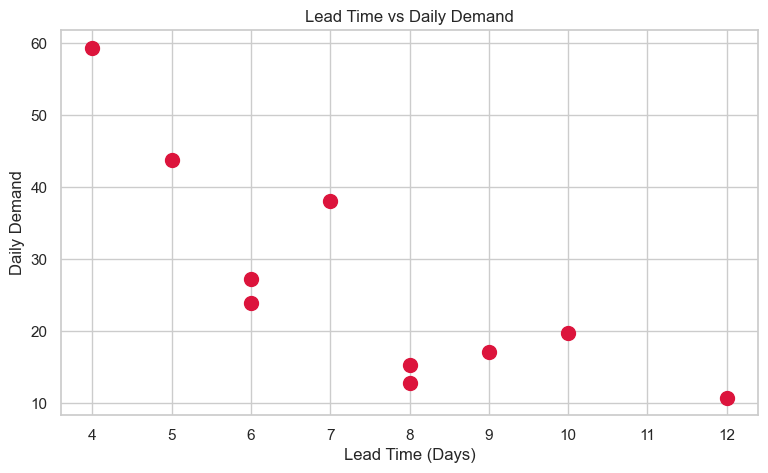

In [1310]:
plt.figure(figsize=(9, 5))

plt.scatter(
    final_inventory["Lead_Time_Days"],
    final_inventory["Daily_Demand"],
    color="crimson",
    s=100,
    marker="o"
)

plt.title("Lead Time vs Daily Demand")
plt.xlabel("Lead Time (Days)")
plt.ylabel("Daily Demand")
plt.grid(True)
plt.show()

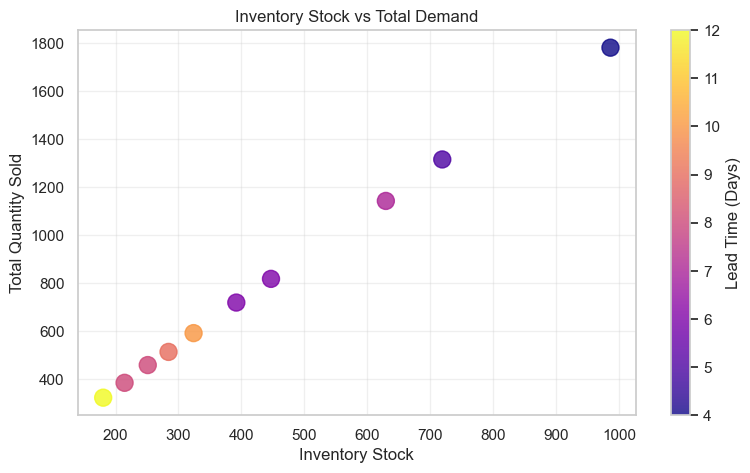

In [1311]:
plt.figure(figsize=(9, 5))

plt.scatter(
    final_inventory["Inventory_Stock"],
    final_inventory["Quantity_Sold_x"],
    s=150,
    c=final_inventory["Lead_Time_Days"],
    cmap="plasma",
    alpha=0.8
)

plt.colorbar(label="Lead Time (Days)")
plt.title("Inventory Stock vs Total Demand")
plt.xlabel("Inventory Stock")
plt.ylabel("Total Quantity Sold")
plt.grid(alpha=0.3)
plt.show()

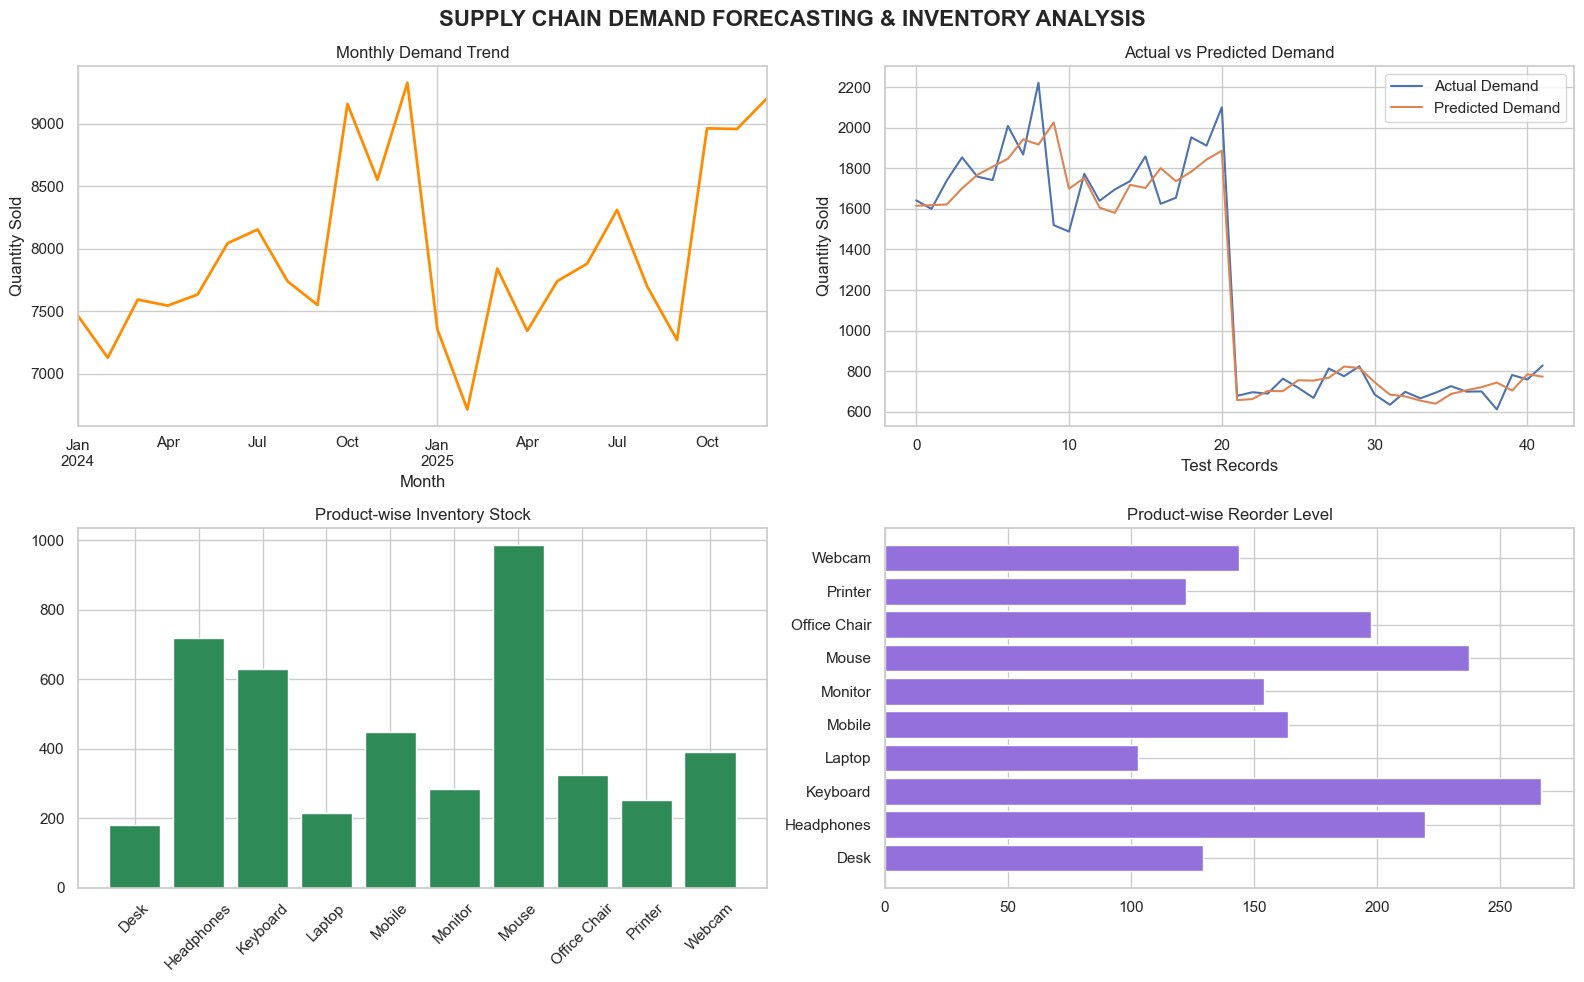

In [1312]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Monthly Demand Trend
monthly_demand.plot(
    ax=axes[0, 0],
    color="darkorange",
    linewidth=2
)
axes[0, 0].set_title("Monthly Demand Trend")
axes[0, 0].set_xlabel("Month")
axes[0, 0].set_ylabel("Quantity Sold")

# 2. Actual vs Predicted Demand
axes[0, 1].plot(y_test.values, label="Actual Demand")
axes[0, 1].plot(y_pred, label="Predicted Demand")
axes[0, 1].set_title("Actual vs Predicted Demand")
axes[0, 1].set_xlabel("Test Records")
axes[0, 1].set_ylabel("Quantity Sold")
axes[0, 1].legend()

# 3. Product-wise Inventory Stock
axes[1, 0].bar(
    final_inventory["Product_Name"],
    final_inventory["Inventory_Stock"],
    color="seagreen"
)
axes[1, 0].set_title("Product-wise Inventory Stock")
axes[1, 0].tick_params(axis="x", rotation=45)

# 4. Product-wise Reorder Level
axes[1, 1].barh(
    final_inventory["Product_Name"],
    final_inventory["Reorder_Level"],
    color="mediumpurple"
)
axes[1, 1].set_title("Product-wise Reorder Level")

fig.suptitle(
    "SUPPLY CHAIN DEMAND FORECASTING & INVENTORY ANALYSIS",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [1313]:
print("Total Revenue:", df["Revenue_INR"].sum())
print("Total Quantity Sold:", df["Quantity_Sold"].sum())
print("Total Products:", df["Product_ID"].nunique())
print("Average Lead Time:", df["Lead_Time_Days"].mean())

Total Revenue: 1342095000
Total Quantity Sold: 191219
Total Products: 10
Average Lead Time: 7.5


Business Insights

1. The dataset contains 10 unique products across different categories.
2. The total revenue generated is ₹1,342,095,000.
3. The total quantity sold is 191,219 units.
4. The average supplier lead time is 7.5 days.
5. Demand forecasting can help estimate future product requirements.
6. Inventory analysis helps identify stock availability and reorder requirements.

Note: This project uses a synthetic dataset for educational and portfolio purposes.

Project Conclusion

This project demonstrates how Python and Machine Learning can be used for supply chain demand forecasting and inventory analysis.

The Linear Regression model was trained to predict product demand using historical sales data. Model performance was evaluated using MAE, RMSE, and R² Score.

Inventory analysis was performed to understand stock availability and estimate reorder levels based on daily demand and supplier lead time.

The dashboard presents important insights through visualizations, helping users understand demand patterns, predicted demand, inventory levels, and reorder requirements.

Tools Used: Python, Pandas, NumPy, Matplotlib, Scikit-learn, Jupyter Notebook.

Note: This project uses a synthetic dataset for learning and portfolio demonstration.